In [1]:
# Imports
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn import metrics
from google.colab import drive

# Connect to Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Read the Housing.csv
file_path = '/content/drive/My Drive/Datasets/Housing.csv'
df = pd.DataFrame(pd.read_csv(file_path))
print('Number of examples m =', len(df))
df.head()

Number of examples m = 545


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
# Preprocessing
# Map yes/no variables to 1/0
binary_vars = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
df[binary_vars] = df[binary_vars].apply(lambda x: x.map({'yes': 1, 'no': 0}))

In [4]:
# One-hot encoding of furnishingstatus
df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True, dtype=float)

In [5]:
# Input variables: all columns except the price
variables = [c for c in df.columns if c != 'price']
print(variables)

['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


In [6]:
# 80/20 split into training and test set
df_train, df_test = train_test_split(df, train_size=0.8, test_size=0.2, random_state=100)

In [7]:
# The training set is split again 80/20 into a smaller training set and a validation set
# The validation set is used for the loss curves and to choose the network, the test set is only used for the final evaluation
df_tr, df_val = train_test_split(df_train, train_size=0.8, test_size=0.2, random_state=100)
print('Training examples:', len(df_train), f'({len(df_tr)} for training + {len(df_val)} for validation)',
      '| Test examples:', len(df_test))

Training examples: 436 (348 for training + 88 for validation) | Test examples: 109


In [8]:
# Standardization of the inputs: the scaler is fitted on the training set only
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(df_train[variables].values.astype(float))
X_tr = scaler_X.transform(df_tr[variables].values.astype(float))
X_val = scaler_X.transform(df_val[variables].values.astype(float))
X_test = scaler_X.transform(df_test[variables].values.astype(float))
y_train, y_tr, y_val, y_test = df_train['price'].values, df_tr['price'].values, df_val['price'].values, df_test['price'].values

In [9]:
# The price is also standardized for the training and transformed back for the evaluation
scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()

def scale_y(y):
    return scaler_y.transform(y.reshape(-1, 1)).ravel()

def to_price(y_s):
    return scaler_y.inverse_transform(y_s.reshape(-1, 1)).ravel()

def evaluate(y, y_pred):
    mse = metrics.mean_squared_error(y, y_pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': metrics.r2_score(y, y_pred)}

## 1.a) Fully connected neural network

In [10]:
# Convert to PyTorch tensors
def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

train_x, tr_x, val_x, test_x = to_tensor(X_train), to_tensor(X_tr), to_tensor(X_val), to_tensor(X_test)
train_y = to_tensor(y_train_s).unsqueeze(1)
tr_y = to_tensor(scale_y(y_tr)).unsqueeze(1)
val_y = to_tensor(scale_y(y_val)).unsqueeze(1)

In [11]:
# DataLoader for the minibatches (shuffled in every epoch)
batch_size = 16
def make_loader(x, y):
    return torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x, y), batch_size=batch_size, shuffle=True)

In [12]:
# Training loop from the lecture with minibatches and a validation loss per epoch
# (without validation data only the training loss is recorded)
def training_loop(n_epochs, optimizer, model, loss_fn, train_loader, val_x=None, val_y=None):
    history = {'train_loss': [], 'val_loss': []}
    for epoch in range(1, n_epochs + 1):
        model.train()
        total_loss = 0
        for x_batch, y_batch in train_loader:
            outputs = model(x_batch)
            loss = loss_fn(outputs, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x_batch)
        history['train_loss'].append(total_loss / len(train_loader.dataset))

        # No gradient needed for the validation set
        if val_x is not None:
            model.eval()
            with torch.no_grad():
                history['val_loss'].append(loss_fn(model(val_x), val_y).item())
            if epoch == 1 or epoch % 100 == 0:
                print(f'Epoch {epoch}, Training loss {history["train_loss"][-1]:.4f}, '
                      f'Validation loss {history["val_loss"][-1]:.4f}')
    return history

In [13]:
# Small experiment with different hidden layer sizes and activation functions
def build_model(h1, h2, activation):
    return nn.Sequential(
        nn.Linear(len(variables), h1),
        activation(),
        nn.Linear(h1, h2),
        activation(),
        nn.Linear(h2, 1))

configs = [(16, 8, nn.ReLU), (32, 16, nn.ReLU), (64, 32, nn.ReLU), (32, 16, nn.Tanh)]
learning_rate = 1e-3
n_epochs = 300
nn_results = {}

for h1, h2, activation in configs:
    name = f'{len(variables)}-{h1}-{h2}-1 {activation.__name__}'
    print(f'\n--- {name} ---')
    torch.manual_seed(0)  # same start weights and batch order for every run
    model = build_model(h1, h2, activation)
    optimizer = optim.SGD(model.parameters(), lr=learning_rate)
    history = training_loop(n_epochs, optimizer, model, nn.MSELoss(), make_loader(tr_x, tr_y), val_x, val_y)

    with torch.no_grad():
        y_pred_val = to_price(model(val_x).numpy().ravel())
    n_params = sum(p.numel() for p in model.parameters())
    nn_results[name] = {'config': (h1, h2, activation), 'history': history, 'params': n_params,
                        **evaluate(y_val, y_pred_val)}

print('\nValidation results:')
for name, r in nn_results.items():
    print(f"{name:<18} | parameters={r['params']:<5} | MSE={r['MSE']:.4e} | RMSE={r['RMSE']:.0f} | R2={r['R2']:.4f}")


--- 13-16-8-1 ReLU ---
Epoch 1, Training loss 1.0675, Validation loss 1.0020
Epoch 100, Training loss 0.3394, Validation loss 0.4429
Epoch 200, Training loss 0.2768, Validation loss 0.4149
Epoch 300, Training loss 0.2629, Validation loss 0.4119

--- 13-32-16-1 ReLU ---
Epoch 1, Training loss 0.9252, Validation loss 0.9150
Epoch 100, Training loss 0.2907, Validation loss 0.4508
Epoch 200, Training loss 0.2664, Validation loss 0.4199
Epoch 300, Training loss 0.2543, Validation loss 0.4069

--- 13-64-32-1 ReLU ---
Epoch 1, Training loss 1.0598, Validation loss 1.0080
Epoch 100, Training loss 0.2821, Validation loss 0.4224
Epoch 200, Training loss 0.2506, Validation loss 0.4034
Epoch 300, Training loss 0.2336, Validation loss 0.3961

--- 13-32-16-1 Tanh ---
Epoch 1, Training loss 0.8594, Validation loss 0.8042
Epoch 100, Training loss 0.3467, Validation loss 0.4122
Epoch 200, Training loss 0.3285, Validation loss 0.3919
Epoch 300, Training loss 0.3171, Validation loss 0.3852

Validation r

In [14]:
# Selected network = highest R2 on the validation set
best_name = max(nn_results, key=lambda n: nn_results[n]['R2'])
best = nn_results[best_name]
print('\nSelected network:', best_name)


Selected network: 13-32-16-1 Tanh


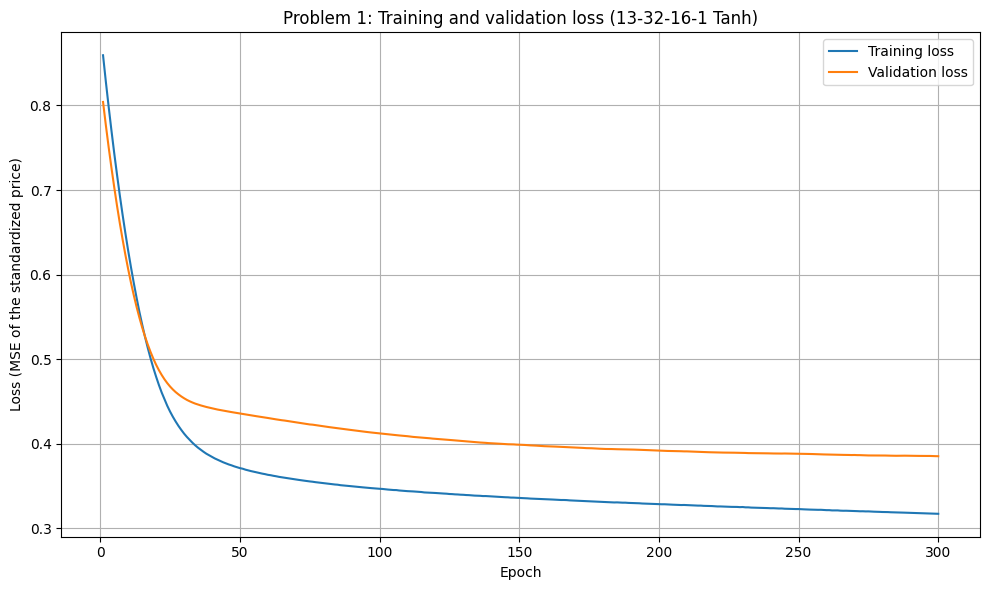

In [15]:
# Plot training and validation loss of the selected network
epochs = range(1, n_epochs + 1)
plt.figure(figsize=(10, 6))
plt.plot(epochs, best['history']['train_loss'], label='Training loss')
plt.plot(epochs, best['history']['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE of the standardized price)')
plt.title(f'Problem 1: Training and validation loss ({best_name})')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('problem_1_loss.png', dpi=110)
plt.show()

In [16]:
# Final model: the selected network is trained again on the whole training set (80%), so it uses the same training data as the linear regression and the SVR
torch.manual_seed(0)
final_model = build_model(*best['config'])
print(final_model)
optimizer = optim.SGD(final_model.parameters(), lr=learning_rate)
training_loop(n_epochs, optimizer, final_model, nn.MSELoss(), make_loader(train_x, train_y))

with torch.no_grad():
    y_pred_nn = to_price(final_model(test_x).numpy().ravel())
    train_r2 = metrics.r2_score(y_train, to_price(final_model(train_x).numpy().ravel()))
results_nn = evaluate(y_test, y_pred_nn)
print(f"Neural network on the test set: MSE={results_nn['MSE']:.4e} | RMSE={results_nn['RMSE']:.0f} "
      f"| R2={results_nn['R2']:.4f} (training R2={train_r2:.4f})")

Sequential(
  (0): Linear(in_features=13, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): Tanh()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
Neural network on the test set: MSE=1.1282e+12 | RMSE=1062184 | R2=0.6803 (training R2=0.6795)


## 1.b) Comparison with linear regression and SVR

In [17]:
# Linear regression with gradient descent from Homework 2
def compute_cost(X, y, theta):
    m = len(y)
    errors = X.dot(theta) - y
    return 1 / (2 * m) * np.sum(np.square(errors))

def gradient_descent(X, y, theta, alpha, iterations):
    m = len(y)
    cost_history = np.zeros(iterations)
    for i in range(iterations):
        errors = X.dot(theta) - y
        theta = theta - alpha * (1 / m) * X.transpose().dot(errors)
        cost_history[i] = compute_cost(X, y, theta)
    return theta, cost_history

In [18]:
# Add the X_0 column of ones
X_train_lr = np.hstack((np.ones((len(X_train), 1)), X_train))
X_test_lr = np.hstack((np.ones((len(X_test), 1)), X_test))
theta, cost_history = gradient_descent(X_train_lr, y_train, np.zeros(X_train_lr.shape[1]), alpha=0.1, iterations=1000)
y_pred_lr = X_test_lr.dot(theta)
results_lr = evaluate(y_test, y_pred_lr)

In [19]:
# SVR
# Kernel and C are chosen with 5-fold cross-validation on the training set (like in Homework 4)
grid = GridSearchCV(SVR(), {'kernel': ['linear', 'poly', 'rbf'], 'C': [0.1, 1, 10, 100]}, cv=5, scoring='r2')
grid.fit(X_train, y_train_s)
print('Best SVR:', grid.best_params_)
y_pred_svr = to_price(grid.best_estimator_.predict(X_test))
results_svr = evaluate(y_test, y_pred_svr)

Best SVR: {'C': 0.1, 'kernel': 'linear'}


In [20]:
# Compare all three models on the test set
comparison = pd.DataFrame({'Linear regression': results_lr,
                           f"SVR ({grid.best_params_['kernel']}, C={grid.best_params_['C']})": results_svr,
                           f'Neural network ({best_name})': results_nn}).T
print(comparison.to_string(formatters={'MSE': '{:.4e}'.format, 'RMSE': '{:.0f}'.format, 'R2': '{:.4f}'.format}))

                                        MSE    RMSE     R2
Linear regression                1.1271e+12 1061662 0.6807
SVR (linear, C=0.1)              1.0978e+12 1047757 0.6890
Neural network (13-32-16-1 Tanh) 1.1282e+12 1062184 0.6803


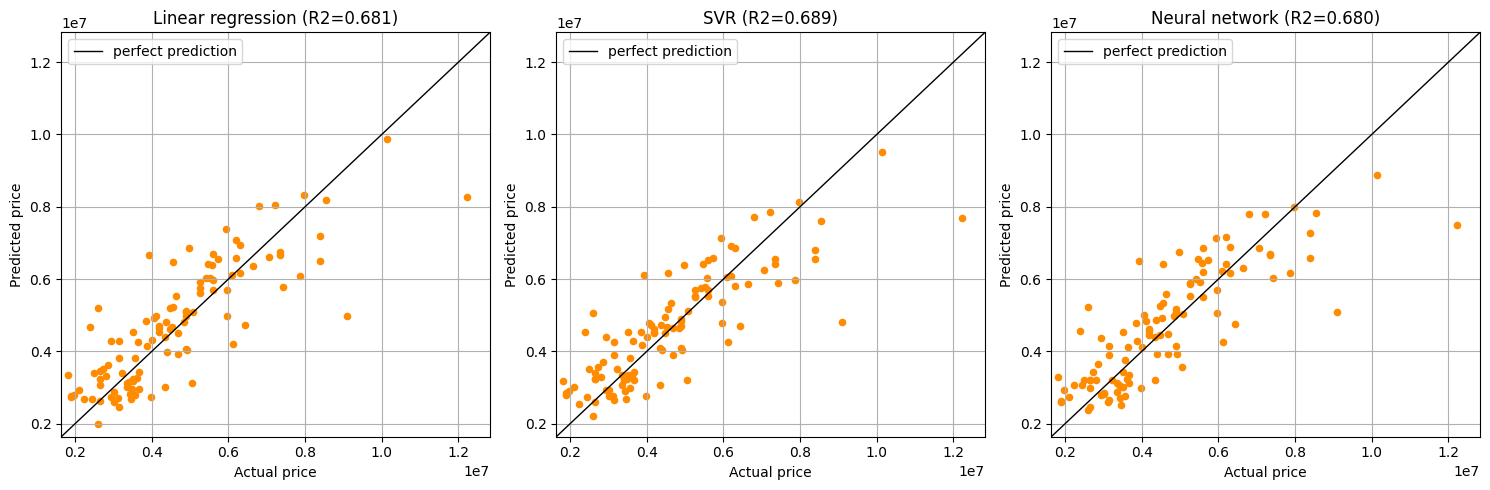

In [21]:
# Predicted vs. actual price on the test set for all three models
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
lims = [y_test.min() * 0.9, y_test.max() * 1.05]
for ax, (name, y_pred) in zip(axes, [('Linear regression', y_pred_lr), ('SVR', y_pred_svr),
                                     ('Neural network', y_pred_nn)]):
    ax.scatter(y_test, y_pred, color='darkorange', s=20)
    ax.plot(lims, lims, color='black', lw=1, label='perfect prediction')
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_title(f'{name} (R2={metrics.r2_score(y_test, y_pred):.3f})')
    ax.set_xlabel('Actual price')
    ax.set_ylabel('Predicted price')
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.savefig('problem_1_pred_vs_actual.png', dpi=110)
plt.show()